# Per-layer bitwise accuracy of the ResNet-18 extraction

Per-layer **bitwise accuracy** (fraction of float16 weights recovered bit-exact vs the
ground-truth pretrained ResNet-18) of the 200k extraction run (multi-patch, `run200k.sbatch`).

The numbers are computed by `python postprocess.py` from the per-filter pickles and the
ground truth in `model_weights/`, and read here from `data/resnet_bitwise_acc.csv`
(metric == `calcAccBitwise`).

For complete layers all filters are present → bitwise acc over the whole layer. For a **crash layer** only
some filter indices are present → bitwise acc is computed only over those present filters, each compared to
its **same-index** ground-truth filter. Layers are numbered `conv1 … conv20`, with the final `FC` layer
kept on the axis.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Plot-only notebook: the numbers are produced by `python postprocess.py` (-> ./data/*.csv)
os.makedirs('../plots/paper', exist_ok=True)

In [2]:
df = pd.read_csv('data/resnet_bitwise_acc.csv')
EXPS = ['Adaptive RF']

# Conv/Linear layers in forward (named_modules) order; FC kept last.
LAYER_ORDER = list(df[df.method == EXPS[0]].layer)
# Sequential display labels: conv1 .. conv20, then FC.
LABELS = list(df[df.method == EXPS[0]].label)

In [3]:
accs = {label: list(df[df.method == label].bitwise_acc) for label in EXPS}

print(f"{'layer':22s} {'name':>7s} " + ' '.join(f'{l:>20s}' for l in EXPS))
for xi, layer in enumerate(LAYER_ORDER):
    cells = {}
    for label in EXPS:
        r = df[(df.method == label) & (df.layer == layer)].iloc[0]
        if r.n_present == 0:
            cells[label] = '      --'
        elif r.n_present != r.n_total:
            cells[label] = f'{r.bitwise_acc:.4f} ({r.n_present}/{r.n_total})'
        else:
            cells[label] = f'{r.bitwise_acc:.4f}'
    print(f'{layer:22s} {LABELS[xi]:>7s} ' + ' '.join(f'{cells[l]:>20s}' for l in EXPS))

layer                     name          Adaptive RF
conv1                    conv1               1.0000
layer1.0.conv1           conv2               0.8433
layer1.0.conv2           conv3               1.0000
layer1.1.conv1           conv4               0.9999
layer1.1.conv2           conv5               1.0000
layer2.0.conv1           conv6               1.0000
layer2.0.conv2           conv7               1.0000
layer2.0.downsample.0    conv8               0.9999
layer2.1.conv1           conv9               0.9999
layer2.1.conv2          conv10               0.9919
layer3.0.conv1          conv11               0.9998
layer3.0.conv2          conv12               0.9994
layer3.0.downsample.0   conv13               1.0000
layer3.1.conv1          conv14               0.9988
layer3.1.conv2          conv15               0.9956
layer4.0.conv1          conv16               0.9969
layer4.0.conv2          conv17               0.9967
layer4.0.downsample.0   conv18               0.9996
layer4.1.con

In [4]:
STYLE = {
    'Adaptive RF': dict(color='#1f77b4', marker='o', zorder=3),
}
LEGEND_ORDER = ['Adaptive RF']


def plot_bitwise_acc_per_layer(accs, figsize=(15, 9), font_size=24,
                                marker_size=13, savepath='../plots/resnet_e2e_bitwise_acc.pdf'):
    sns.set(style='whitegrid')
    fig, ax = plt.subplots(figsize=figsize)
    x = np.arange(len(LAYER_ORDER))
    handles = {}
    for label, ys in accs.items():
        y = np.asarray(ys, dtype=float)
        h, = ax.plot(x, y, linewidth=3, markersize=marker_size, label=label, **STYLE.get(label, {}))
        handles[label] = h
    ax.set_xlabel('Network Layer', fontsize=font_size + 2)
    ax.set_ylabel('Bitwise Accuracy', fontsize=font_size + 2)
    ax.set_xticks(x)
    ax.set_xticklabels(LABELS, rotation=-45, ha='center', fontsize=font_size - 6)
    ax.tick_params(axis='y', labelsize=font_size - 2)
    ax.set_ylim(0, 1.005)
    ax.grid(True, which='both', linestyle='--', linewidth=0.7)
    for sp in ax.spines.values():
        sp.set_linewidth(1.5)
    order = [l for l in LEGEND_ORDER if l in handles] + [l for l in handles if l not in LEGEND_ORDER]
    ax.legend([handles[l] for l in order], order, fontsize=font_size, framealpha=0.95)
    plt.tight_layout()
    os.makedirs(os.path.dirname(savepath), exist_ok=True)
    plt.savefig(savepath, format='pdf', bbox_inches='tight')
    plt.savefig(savepath.replace('.pdf', '.png'), format='png', bbox_inches='tight')
    plt.show()

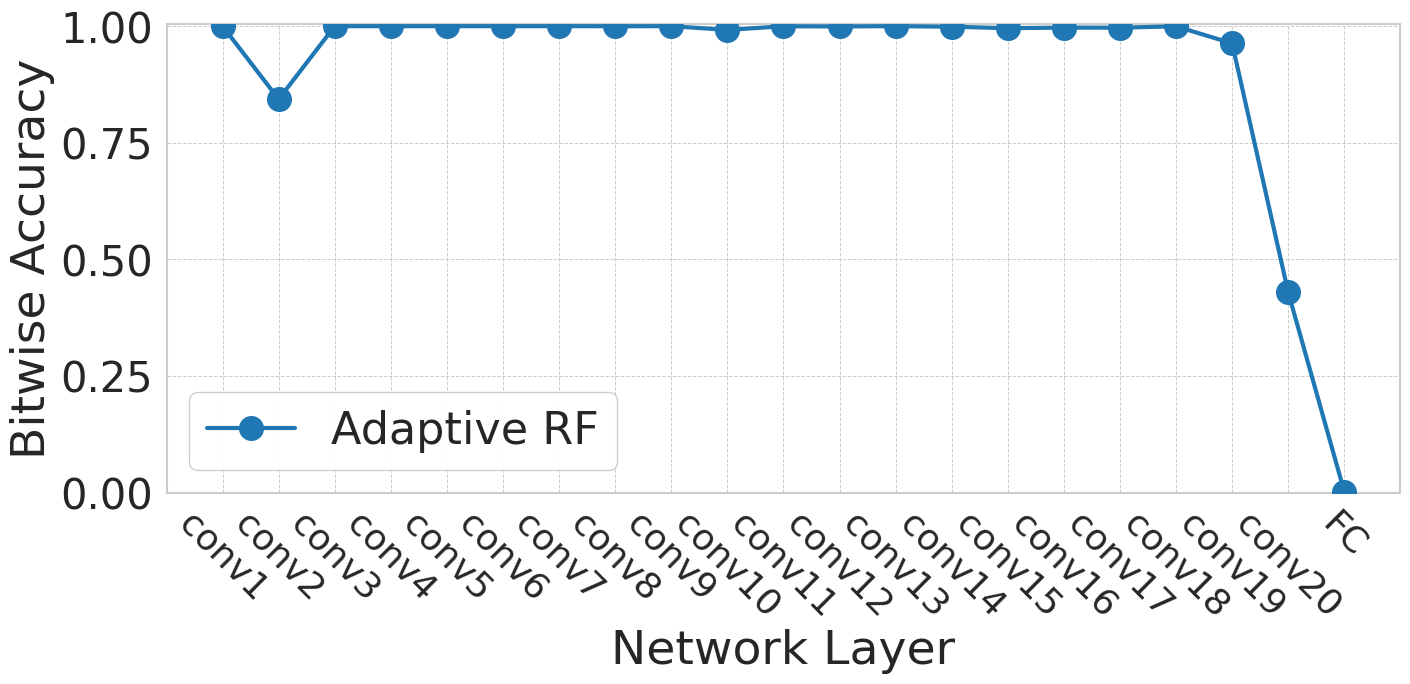

In [5]:
plot_bitwise_acc_per_layer(accs, figsize=(14, 7),
    font_size=32,
    marker_size=17,savepath='../plots/resnet_bitwise_acc.pdf')

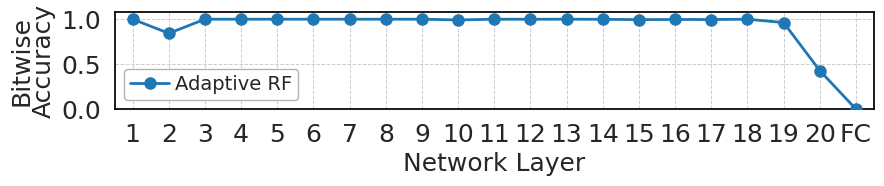

In [6]:
# Squashed copy of resnet_bitwise_acc (cells 5-6): wide and short, 18 pt axis text,
# layers numbered 1..20 + FC with no rotation, one-row legend inside.
# Writes ../plots/paper/resnet_bitwise_acc_squashed.pdf; the original is untouched.
def plot_bitwise_acc_squashed(accs, figsize=(9, 2.0), font_size=18,
                              savepath='../plots/paper/resnet_bitwise_acc_squashed.pdf'):
    sns.set(style='whitegrid')
    fig, ax = plt.subplots(figsize=figsize)
    x = np.arange(len(LAYER_ORDER))
    handles = {}
    for label, ys in accs.items():
        h, = ax.plot(x, np.asarray(ys, dtype=float), linewidth=2.0, markersize=8,
                     label=label, **STYLE.get(label, {}))
        handles[label] = h
    ax.set_xticks(x)
    ax.set_xticklabels([('FC' if l == 'fc' else str(i + 1)) for i, l in enumerate(LAYER_ORDER)])
    ax.set_xlim(-0.5, len(LAYER_ORDER) - 0.5)
    ax.set_ylim(0, 1.08)
    ax.set_yticks([0, 0.5, 1.0])
    ax.set_xlabel('Network Layer', fontsize=font_size)
    ax.set_ylabel('Bitwise\nAccuracy', fontsize=font_size, linespacing=0.9)
    ax.tick_params(axis='both', labelsize=font_size)   # same size on both axes (user)
    ax.grid(True, linestyle='--', linewidth=0.7)
    for sp in ax.spines.values():
        sp.set_color('black')
    order = [l for l in LEGEND_ORDER if l in handles]
    ax.legend([handles[l] for l in order], order, loc='lower left', ncol=len(order),
              fontsize=font_size - 4, frameon=True, facecolor='white', edgecolor='0.7',
              framealpha=1.0, borderpad=0.3, handletextpad=0.3, columnspacing=0.8)
    plt.tight_layout()
    fig.savefig(savepath, format='pdf', bbox_inches='tight')
    plt.show()

plot_bitwise_acc_squashed(accs)
